# Lab 2: Standardization and Normalization



In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler, MinMaxScaler

df = pd.read_csv("datasets/winequality-red.csv")
df.head()


,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.9968,3.20,0.68,9.8,5
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.9970,3.26,0.65,9.8,5
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.9980,3.16,0.58,9.8,6
4,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5


In [2]:
# Some Kaggle copies of the wine dataset use semicolon separators.
if df.shape[1] == 1:
    df = pd.read_csv("dataset.csv", sep=";")

print(df.shape)
print(df.columns)


(1599, 12)
Index(['fixed acidity', 'volatile acidity', 'citric acid', 'residual sugar',
       'chlorides', 'free sulfur dioxide', 'total sulfur dioxide', 'density',
       'pH', 'sulphates', 'alcohol', 'quality'],
      dtype='str')


In [3]:
# Use the numeric input columns, excluding quality
X = df.drop(columns=["quality"])

# Standardization
scaler = StandardScaler()
standard_data = pd.DataFrame(scaler.fit_transform(X), columns=X.columns)

standard_data.head()


,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol
0,-0.528360,0.961877,-1.391472,-0.453218,-0.243707,-0.466193,-0.379133,0.558274,1.288643,-0.579207,-0.960246
1,-0.298547,1.967442,-1.391472,0.043416,0.223875,0.872638,0.624363,0.028261,-0.719933,0.128950,-0.584777
2,-0.298547,1.297065,-1.186070,-0.169427,0.096353,-0.083669,0.229047,0.134264,-0.331177,-0.048089,-0.584777
3,1.654856,-1.384443,1.484154,-0.453218,-0.264960,0.107592,0.411500,0.664277,-0.979104,-0.461180,-0.584777
4,-0.528360,0.961877,-1.391472,-0.453218,-0.243707,-0.466193,-0.379133,0.558274,1.288643,-0.579207,-0.960246


In [4]:
# Normalization
normalizer = MinMaxScaler()
normalized_data = pd.DataFrame(normalizer.fit_transform(X), columns=X.columns)

normalized_data.head()


,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol
0,0.247788,0.397260,0.00,0.068493,0.106845,0.140845,0.098940,0.567548,0.606299,0.137725,0.153846
1,0.283186,0.520548,0.00,0.116438,0.143573,0.338028,0.215548,0.494126,0.362205,0.209581,0.215385
2,0.283186,0.438356,0.04,0.095890,0.133556,0.197183,0.169611,0.508811,0.409449,0.191617,0.215385
3,0.584071,0.109589,0.56,0.068493,0.105175,0.225352,0.190813,0.582232,0.330709,0.149701,0.215385
4,0.247788,0.397260,0.00,0.068493,0.106845,0.140845,0.098940,0.567548,0.606299,0.137725,0.153846


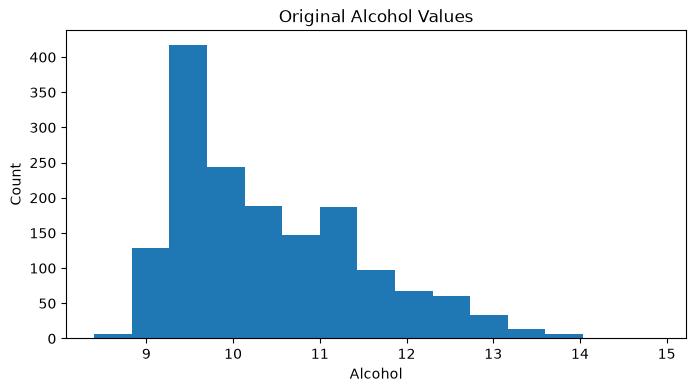

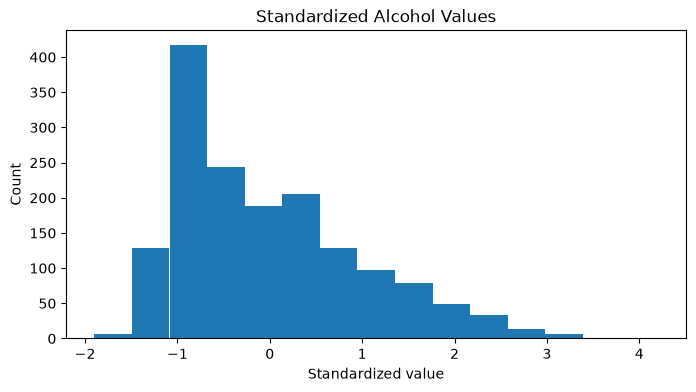

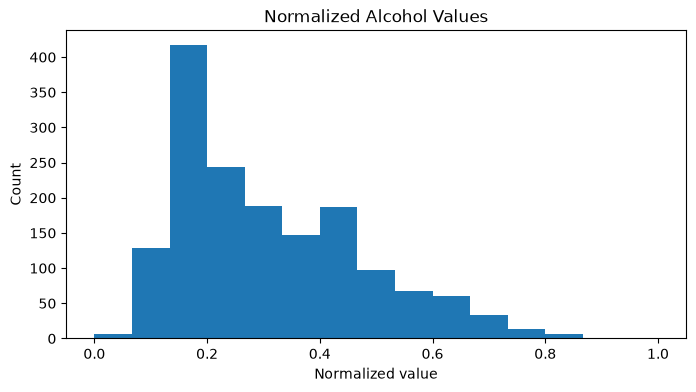

In [5]:
# Compare alcohol values before and after scaling
column = "alcohol"

plt.figure(figsize=(8, 4))
plt.hist(X[column], bins=15)
plt.title("Original Alcohol Values")
plt.xlabel("Alcohol")
plt.ylabel("Count")
plt.show()

plt.figure(figsize=(8, 4))
plt.hist(standard_data[column], bins=15)
plt.title("Standardized Alcohol Values")
plt.xlabel("Standardized value")
plt.ylabel("Count")
plt.show()

plt.figure(figsize=(8, 4))
plt.hist(normalized_data[column], bins=15)
plt.title("Normalized Alcohol Values")
plt.xlabel("Normalized value")
plt.ylabel("Count")
plt.show()
